# Metamodel case generation

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`hs`, `tp`, `dir`, `spr`, `wl`)
   and keep only plausible sea states (steepness `hs / L0 <= max_steepness`), so
   each goal keeps fewer cases than `num_samples_per_goal`.
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from the case JSON → `simulations`.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import simulation as sim
from utils.config import SIMULATIONS, load_goals, resolve, simulation_model

## Configuration

In [2]:
model = simulation_model()
templates_dir = sim.templates_dir("metamodel")
cases_dir = sim.cases_dir("metamodel")
grid_file = sim.grid_file()
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"model     : {model}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"grid      : {grid_file}")
print(f"LHS       : {SIMULATIONS['num_samples_per_goal']} samples per goal")
print(f"bounds    : {SIMULATIONS['bounds']} (dir from each goal sector)")
print(f"steepness : hs / L0 <= {SIMULATIONS['max_steepness']}")

model     : swan
goals     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
templates : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/templates-swan-metamodel
cases     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel
grid      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/Netherlands_mesh.grd
LHS       : 1000 samples per goal
bounds    : {'hs': [0.05, 8.0], 'tp': [1, 15], 'spr': [1, 45], 'wl': [-3.5, 3.5]} (dir from each goal sector)
steepness : hs / L0 <= 0.06


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
print(f"plausible cases per goal: {cases_df.groupby('goal').size().to_dict()}")
cases_df

plausible cases per goal: {1: 629, 2: 629, 3: 629, 4: 629, 5: 629, 6: 629, 7: 629, 8: 629, 9: 629, 10: 629}


,goal,active_node,hs,tp,dir,spr,wl
0,1,1,7.916431,13.936694,261.595022,20.934259,-2.298183
1,1,1,3.963360,10.302466,2.313124,1.361309,-2.914122
2,1,1,2.556438,13.228423,39.457610,9.176931,2.821211
3,1,1,0.125397,12.772378,119.485471,6.861826,-3.322291
4,1,1,0.933107,10.421446,275.515080,19.459789,-2.884436
...,...,...,...,...,...,...,...
6285,10,10,0.215892,7.703696,138.427314,11.935126,-2.348963
6286,10,10,7.731794,11.511080,237.542492,40.345803,-0.604162
6287,10,10,6.089940,9.943996,336.596410,36.348337,-0.079050
6288,10,10,5.630237,12.837076,43.168292,3.853110,-1.641555


In [4]:
from pathlib import Path

map_cases = sorted(
    int(p.parent.name)
    for p in Path("portal_snapwave/SnapWave_CASES_Metamodel").glob("*/*/output_map.nc")
)
cases_df["save_map"] = cases_df.index.isin(map_cases)  # index = case_num 0..6289

In [5]:
cases_df.groupby(["goal", "save_map"])[["tp"]].count()

tp
goal save_map     
1    False     603
     True       26
2    False     597
     True       32
3    False     604
     True       25
4    False     597
     True       32
5    False     601
     True       28
6    False     587
     True       42
7    False     596
     True       33
8    False     594
     True       35
9    False     596
     True       33
10   False     590
     True       39

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [6]:
# Case geometry: goals = boundary nodes, AoI enclosure, labelled output sites
setup = sim.HyWavesWrapperSetup.from_case(raw_goals)

wrapper = setup.metamodel_wrapper(cases_df)
wrapper

In [ ]:
# wrapper.build_cases(
#     cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}",
#     cases_to_build=map_cases,
# )  # rewrites only these 325 INPUTs
# wrapper.run_cases_slurm(cases_to_run=map_cases, **sim.slurm_kwargs(max_parallel=96))

Submitted batch job 894218


In [7]:
setup.output_sites_df

,lon,lat,source,source_id,source_label,depth,name
0,6.776699,53.641063,isobath,5m_0,5m,-5.0,NaN
1,6.788680,53.675962,isobath,5m_1,5m,-5.0,NaN
2,6.864073,53.680102,isobath,5m_2,5m,-5.0,NaN
3,6.922544,53.676656,isobath,5m_3,5m,-5.0,NaN
4,6.738287,53.632106,isobath,5m_4,5m,-5.0,NaN
...,...,...,...,...,...,...,...
402,4.996000,53.320720,buoy,buoy_StortemelkWest,waves,10.0,"Stortemelk, west"
403,2.990000,51.560000,buoy,buoy_ThorntonbankSouthBuoy,waves,32.0,ThorntonbankSouthBuoy
404,6.366670,53.618060,buoy,buoy_WestereemsWest,waves,15.0,"Westereems, west"
405,3.420000,51.430000,buoy,buoy_WielingenNoord,waves,8.0,WielingenNoord


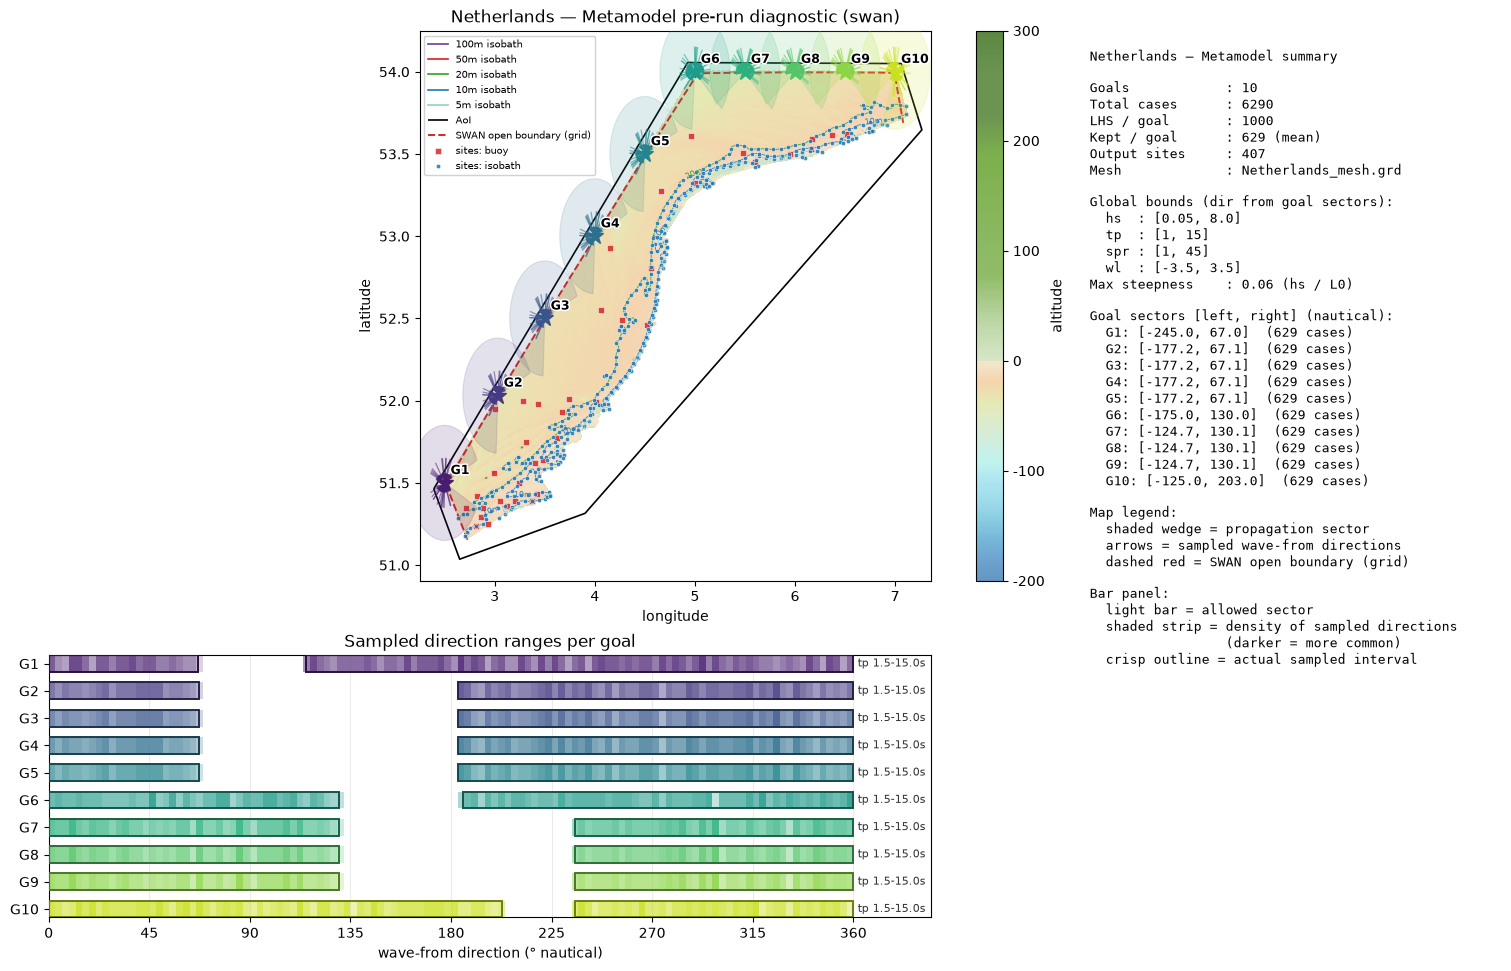

In [8]:
fig = setup.plot_metamodel_configuration(cases_df)
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [9]:
wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [10]:
# On the GeoOcean cluster: one SLURM array task per case. Writes case_dirs.txt
# and the array script into the cases folder (options from
# simulations.<model>.slurm), then submits it with sbatch.
# wrapper.run_cases_slurm(**sim.slurm_kwargs(max_parallel=192))

In [11]:
# Or locally, with snapwave on the PATH:
# wrapper.run_cases_in_background(
#     launcher="""
# module use /nfs/software/geocean/modulefiles
# module load swan
# swan.exe
# """,
#     cases_to_run=[1],
# )

In [11]:
cases_status = wrapper.monitor_cases(value_counts="simple")
cases_status

Status  
FINISHED    6290
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map (or overview fallback)
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

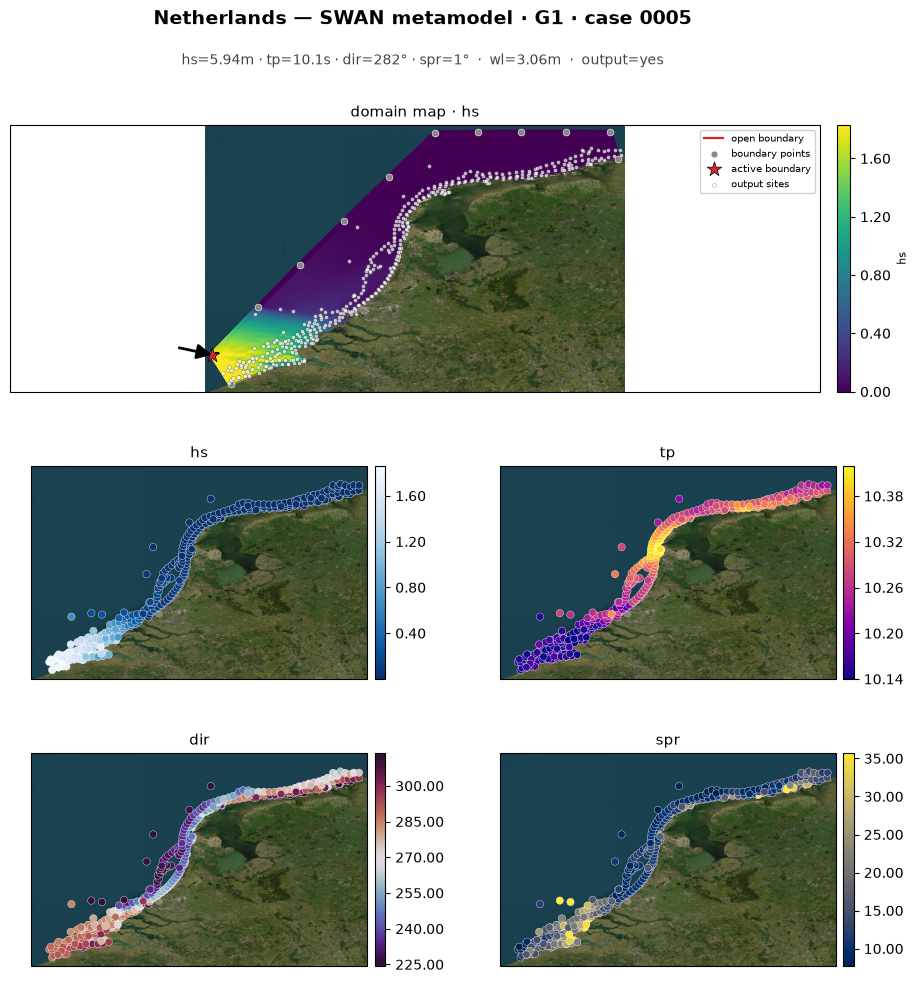

In [13]:
from bluemath_tk.core.plotting.cases import CasePlotStyle
from utils.viz import plot_metamodel_case

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
plot_metamodel_case(cases_dir / "01" / "0005", style=style, show_satellite=True);

In [14]:
wrapper.postprocess_cases()

{1: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_1.nc',
 2: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_2.nc',
 3: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_3.nc',
 4: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_4.nc',
 5: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_5.nc',
 6: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_6.nc',
 7: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_7.nc',
 8: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_8.nc',
 9: '/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Metamodel/output_sites_9.nc',
 10: '/lustre/geoce